# 06 · Financial Risk Engine — commodity VaR/ES and infrastructure credit risk (PD × LGD × EAD)

Two risk books that don't share a dependency structure in this data, so they're built and reported separately rather
than forced into one number:

| Part | Book | Built from |
|---|---|---|
| **A** | Market risk — commodity price VaR/ES | `ds2_ds4_financial_features.csv` (historical simulation, not GARCH — 03 found no volatility clustering to model) |
| **B** | Credit risk — PD × LGD × EAD | `ds3_risk_scores.csv` (05's relative-risk score, rescaled to a known base rate), `severity_lgd_table.csv` (05's empirical LGD), `loan_outstanding_M` (03) |
| **C** | Monte Carlo aggregate loss | 10,000-path compound simulation over Part B's per-bridge PD/LGD/EAD, the scale the workbook's `DS5_Stress_Scenarios` sheet names |
| **D** | Premiums vs. risk | are the premiums collected anywhere close to the risk-based EL computed here? |

**Calibration note carried forward from 05:** the case-control classifier's `relative_risk_score` is a ranking, not a
probability — it was trained on an artificial 16.8%-positive sample, not the true population rate. Part B turns it into
an annual PD by rescaling so the *population mean* matches the known rate (1,011 bridge failures / 19 years / 5,000
bridges), preserving the model's ranking while fixing its scale.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
get_ipython().run_line_magic("matplotlib", "inline")

warnings.filterwarnings("ignore")
ROOT = None
for c in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (c / "src").exists() and (c / "data").exists():
        ROOT = c; break
sys.path.insert(0, str(ROOT))

PROC, TAB, FIG = ROOT/"data/processed", ROOT/"outputs/tables", ROOT/"outputs/figures"
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10})
sns.set_palette("tab10")
SEED = 42
rng = np.random.default_rng(SEED)

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / name, dpi=130, bbox_inches="tight"); plt.show()

fin = pd.read_csv(PROC / "ds2_ds4_financial_features.csv", parse_dates=["date"])
d3 = pd.read_csv(PROC / "ds3_risk_scores.csv")
d3_full = pd.read_csv(PROC / "ds3_exposure_features.csv")
d6 = pd.read_csv(PROC / "ds6_failure_features.csv")
sev = pd.read_csv(TAB / "severity_lgd_table.csv", index_col=0)
sev["empirical_share"] = sev.n / sev.n.sum()
print("financial panel:", fin.shape, "| DS3 risk scores:", d3.shape, "| commodities:", sorted(fin.commodity.unique()))

financial panel: (22952, 55) | DS3 risk scores: (5000, 11) | commodities: ['Aluminium', 'Cobalt_Index', 'Copper', 'Iron_Ore', 'Lithium_ETF', 'Nickel', 'RareEarth_ETF', 'Steel_HRC']


## Part A · Commodity market risk — historical simulation VaR/ES
*Question: 03 found no basis for GARCH/EWMA (no documented volatility clustering), so VaR/ES here use historical
simulation directly on realised returns — no distributional assumption. Two checks worth doing explicitly rather than
assuming: does √21-scaling the 1-day VaR match the *actual* 21-day VaR (it only would under i.i.d. returns), and how
correlated are these eight commodities (naive diversification assumptions could be badly wrong if they move together)?*

,VaR95_1d,ES95_1d,VaR99_1d,ES99_1d,ann_vol,VaR95_21d_actual,VaR95_21d_sqrtscaled,scaling_ratio
commodity,,,,,,,,
Aluminium,0.0252,0.0310,0.0350,0.0387,0.2418,0.1166,0.1154,1.0104
Cobalt_Index,0.0332,0.0424,0.0472,0.0558,0.3180,0.1570,0.1520,1.0335
Copper,0.0264,0.0326,0.0367,0.0417,0.2522,0.1411,0.1208,1.1683
Iron_Ore,0.0329,0.0433,0.0495,0.0588,0.3243,0.1549,0.1507,1.0280
Lithium_ETF,0.0405,0.0523,0.0589,0.0698,0.3981,0.1994,0.1858,1.0730
Nickel,0.0353,0.0440,0.0497,0.0570,0.3428,0.1542,0.1618,0.9535
RareEarth_ETF,0.0460,0.0580,0.0642,0.0752,0.4374,0.2100,0.2106,0.9972
Steel_HRC,0.0296,0.0376,0.0430,0.0489,0.2876,0.1331,0.1355,0.9819


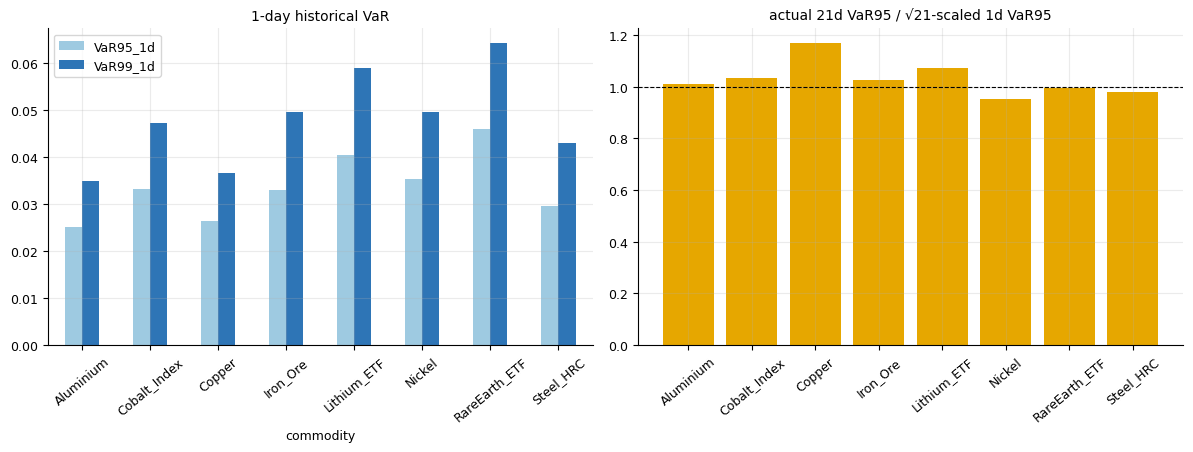

ratios close to 1 (0.95-1.17 here) -> √time scaling is a reasonable approximation for most of these commodities,
with Copper the largest deviation (actual 21d risk running ahead of the scaled estimate) -- worth flagging, not over-reading from one commodity.


In [2]:
def hist_var_es(returns, alpha):
    returns = pd.Series(returns).dropna()
    var = -np.percentile(returns, 100 * (1 - alpha))
    es = -returns[returns <= -var].mean()
    return var, es

rows = []
for c, g in fin.groupby("commodity"):
    v95, e95 = hist_var_es(g.daily_return, .95); v99, e99 = hist_var_es(g.daily_return, .99)
    v95_21, _ = hist_var_es(g.fwd_ret_21, .95)
    scaled_21 = v95 * np.sqrt(21)
    rows.append({"commodity": c, "VaR95_1d": v95, "ES95_1d": e95, "VaR99_1d": v99, "ES99_1d": e99,
                 "ann_vol": g.daily_return.std() * np.sqrt(252), "VaR95_21d_actual": v95_21,
                 "VaR95_21d_sqrtscaled": scaled_21, "scaling_ratio": v95_21 / scaled_21})
var_table = pd.DataFrame(rows).set_index("commodity").round(4)
display(var_table)
var_table.to_csv(TAB / "commodity_var_es.csv")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
var_table[["VaR95_1d", "VaR99_1d"]].plot.bar(ax=ax[0], color=["#9ecae1", "#2e75b6"]); ax[0].set_title("1-day historical VaR"); ax[0].tick_params(axis="x", rotation=40)
ax[1].bar(var_table.index, var_table.scaling_ratio, color="#e6a700"); ax[1].axhline(1, color="k", ls="--", lw=.8)
ax[1].set_title("actual 21d VaR95 / √21-scaled 1d VaR95"); ax[1].tick_params(axis="x", rotation=40)
savefig("06A_var_scaling.png")
print("ratios close to 1 (0.95-1.17 here) -> √time scaling is a reasonable approximation for most of these commodities,")
print("with Copper the largest deviation (actual 21d risk running ahead of the scaled estimate) -- worth flagging, not over-reading from one commodity.")

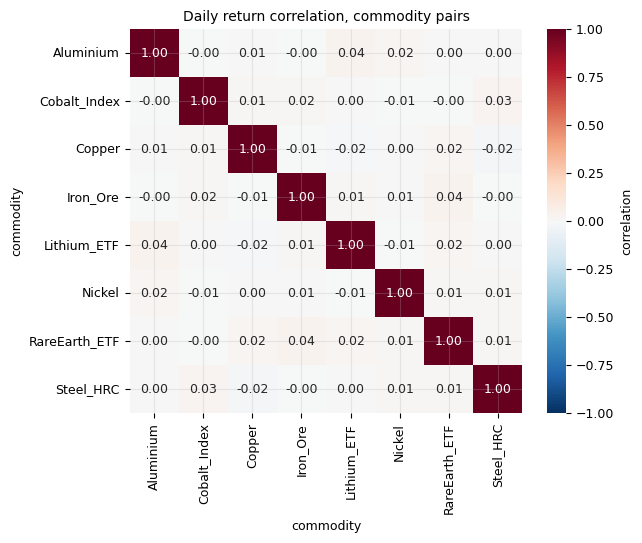

equal-weight basket VaR95(1d)=0.0126 vs. mean of individual VaR95s=0.0336 -- diversification benefit: 62.6%


In [3]:
pivot = fin.pivot(index="date", columns="commodity", values="daily_return")
corr = pivot.corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "correlation"})
ax.set_title("Daily return correlation, commodity pairs")
savefig("06A_commodity_correlation.png")

# equal-weight "material cost basket" (explicit simplification: no true portfolio weights in the data)
basket = pivot.mean(axis=1)
bv95, be95 = hist_var_es(basket, .95)
undiversified = var_table.VaR95_1d.mean()
print(f"equal-weight basket VaR95(1d)={bv95:.4f} vs. mean of individual VaR95s={undiversified:.4f} -- diversification benefit: {(1 - bv95/undiversified):.1%}")

## Part B · Credit risk — PD × LGD × EAD

population base rate: 1.0642%/yr | rescale factor applied to relative_risk_score: 0.1017
PD_annual: mean=1.0642% (matches population rate by construction) | max=5.9236%
blended LGD: capped=0.291  uncapped=0.300  (severity mix x mean loss ratio per band, from 05 Part C)

portfolio: EAD=$1876.8M | annual EL=$5.82M (0.310% of EAD)


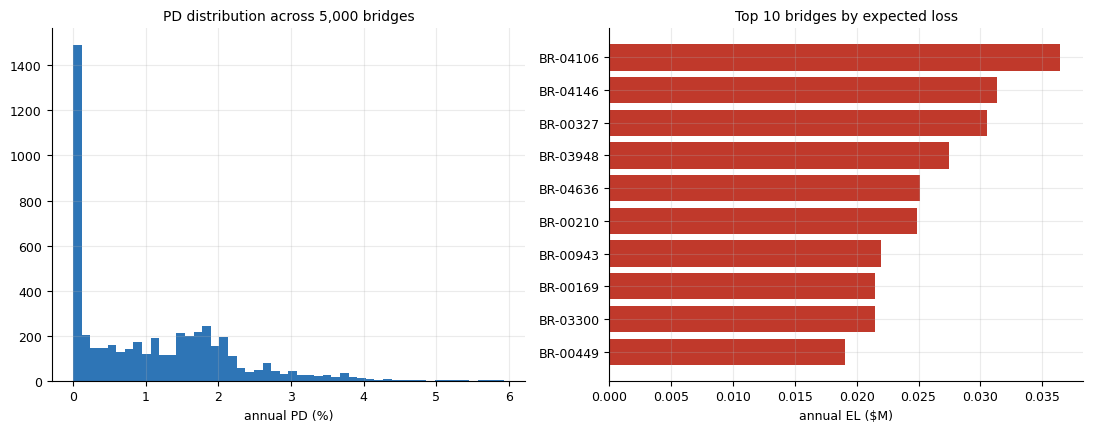

,bridge_id,material,corrosion_environment,PD_annual,EAD_M,EL_M
4105,BR-04106,Steel (A588 Weathering),Mild,0.0275,4.56,0.0365
4145,BR-04146,Prestressed Concrete,Mild,0.0314,3.44,0.0314
326,BR-00327,Composite Steel-Concrete,Mild,0.0381,2.76,0.0305
3947,BR-03948,Steel (A588 Weathering),Mild,0.0346,2.73,0.0274
4635,BR-04636,Steel (A36),Mild,0.0198,4.38,0.0251
209,BR-00210,Reinforced Concrete,Severe,0.0574,1.49,0.0248
942,BR-00943,Steel (A36),Mild,0.0206,3.67,0.0220
168,BR-00169,Reinforced Concrete,Moderate,0.0402,1.84,0.0215
3299,BR-03300,Reinforced Concrete,Severe,0.0224,3.30,0.0214
448,BR-00449,Steel (A36),Mild,0.0195,3.36,0.0191


In [4]:
TRUE_ANNUAL_PD = (1011 / 19) / 5000   # 1,011 DS6 bridge failures over 2005-2023 (19 yrs) / 5,000 DS3 bridges
scale = TRUE_ANNUAL_PD / d3.relative_risk_score.mean()
d3["PD_annual"] = d3.relative_risk_score * scale
print(f"population base rate: {TRUE_ANNUAL_PD:.4%}/yr | rescale factor applied to relative_risk_score: {scale:.4f}")
print(f"PD_annual: mean={d3.PD_annual.mean():.4%} (matches population rate by construction) | max={d3.PD_annual.max():.4%}")

LGD_capped = (sev.empirical_share * sev.mean_lr_cap).sum()
LGD_uncapped = (sev.empirical_share * sev.mean_loss_ratio).sum()
print(f"blended LGD: capped={LGD_capped:.3f}  uncapped={LGD_uncapped:.3f}  (severity mix x mean loss ratio per band, from 05 Part C)")

d3["LGD"] = LGD_capped
d3["EAD_M"] = d3.loan_outstanding_M   # EAD = outstanding loan balance, not replacement cost
d3["EL_M"] = d3.PD_annual * d3.LGD * d3.EAD_M
print(f"\nportfolio: EAD=${d3.EAD_M.sum():.1f}M | annual EL=${d3.EL_M.sum():.2f}M ({d3.EL_M.sum()/d3.EAD_M.sum():.3%} of EAD)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ax[0].hist(d3.PD_annual * 100, bins=50, color="#2e75b6"); ax[0].set_xlabel("annual PD (%)"); ax[0].set_title("PD distribution across 5,000 bridges")
top10 = d3.nlargest(10, "EL_M")[["bridge_id", "material", "corrosion_environment", "PD_annual", "EAD_M", "EL_M"]]
ax[1].barh(top10.bridge_id, top10.EL_M, color="#c0392b"); ax[1].set_xlabel("annual EL ($M)"); ax[1].set_title("Top 10 bridges by expected loss"); ax[1].invert_yaxis()
savefig("06B_credit_risk.png")
display(top10.round(4))
d3.to_csv(PROC / "ds3_credit_risk.csv", index=False)

## Part C · Monte Carlo aggregate loss (10,000 paths)
Per bridge: `Bernoulli(PD_i)` for failure, then — conditional on failure — a severity class drawn from the empirical mix
and a loss ratio resampled from DS6's actual within-severity values (not a fitted parametric distribution; the EDA never
found one that was needed). This is the Monte Carlo structure the workbook's `DS5_Stress_Scenarios` sheet names; 07 will
reuse this same engine under shocked PD/severity inputs.

MC mean annual loss: $5.83M (closed-form EL was $5.82M -- should match closely)
MC VaR95=$8.82M  VaR99=$10.43M  ES95=$9.83M
mean simulated failures/yr: 53.2 (population base rate implies 53.2/yr)


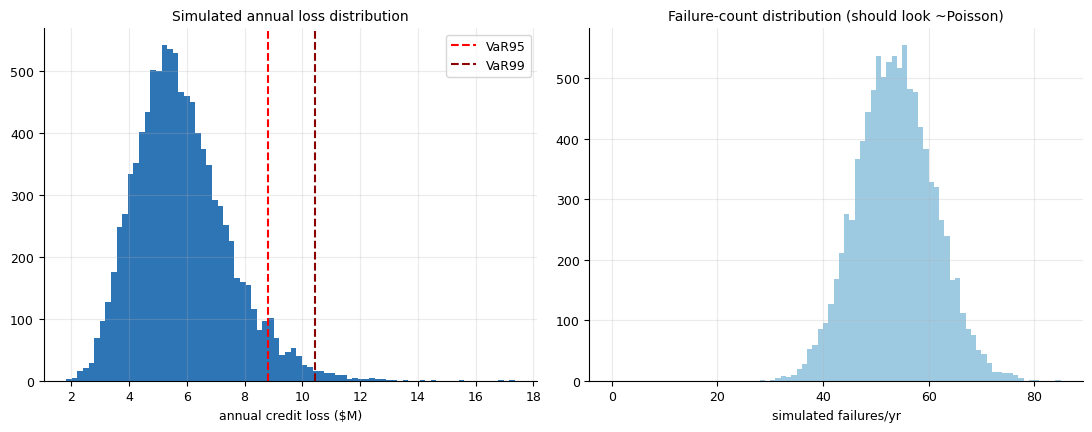

In [5]:
N_SIMS = 10000
PD = d3.PD_annual.values; EAD = d3.EAD_M.values
sev_classes = sev.index.tolist(); sev_probs = sev.empirical_share.values
loss_by_sev = {s: d6.loc[d6.severity == s, "lr_cap"].values for s in sev_classes}

def simulate_annual_losses(pd_arr, ead_arr, n_sims=N_SIMS, seed=SEED):
    g = np.random.default_rng(seed)
    totals = np.zeros(n_sims); n_fails = np.zeros(n_sims, dtype=int)
    for i in range(n_sims):
        fails = g.random(len(pd_arr)) < pd_arr
        n_fails[i] = fails.sum()
        if n_fails[i] == 0: continue
        chosen = g.choice(sev_classes, size=n_fails[i], p=sev_probs)
        lr = np.array([g.choice(loss_by_sev[s]) for s in chosen])
        totals[i] = (lr * ead_arr[fails]).sum()
    return totals, n_fails

losses, n_fails = simulate_annual_losses(PD, EAD)
print(f"MC mean annual loss: ${losses.mean():.2f}M (closed-form EL was ${d3.EL_M.sum():.2f}M -- should match closely)")
print(f"MC VaR95=${np.percentile(losses,95):.2f}M  VaR99=${np.percentile(losses,99):.2f}M  ES95=${losses[losses>=np.percentile(losses,95)].mean():.2f}M")
print(f"mean simulated failures/yr: {n_fails.mean():.1f} (population base rate implies {TRUE_ANNUAL_PD*5000:.1f}/yr)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ax[0].hist(losses, bins=80, color="#2e75b6"); ax[0].axvline(np.percentile(losses, 95), color="r", ls="--", label="VaR95"); ax[0].axvline(np.percentile(losses, 99), color="darkred", ls="--", label="VaR99")
ax[0].set_xlabel("annual credit loss ($M)"); ax[0].legend(); ax[0].set_title("Simulated annual loss distribution")
ax[1].hist(n_fails, bins=range(0, n_fails.max()+2), color="#9ecae1"); ax[1].set_xlabel("simulated failures/yr"); ax[1].set_title("Failure-count distribution (should look ~Poisson)")
savefig("06C_monte_carlo_losses.png")

mc_summary = pd.DataFrame([{"mean_annual_loss_M": losses.mean(), "VaR95_M": np.percentile(losses, 95), "VaR99_M": np.percentile(losses, 99),
                            "ES95_M": losses[losses >= np.percentile(losses, 95)].mean(), "mean_failures_per_year": n_fails.mean()}])
mc_summary.to_csv(TAB / "credit_monte_carlo_summary.csv", index=False)

## Part D · Are premiums anywhere near risk-based?
03's audit found `insurance_premium_K_yr` barely correlated with condition or corrosion rate. Compare the premium pool
actually collected against the EL computed here — not as a judgement on the business (a real insurer prices in capital
charges, catastrophe load and margin on top of EL), just as a factual comparison.

total annual premiums collected: $56.4M
total risk-based annual EL (this notebook): $5.8M
premium / EL ratio: 9.7x


,PD_annual,EL_M,insurance_premium_K_yr
PD_annual,1.000,0.531,-0.003
EL_M,0.531,1.000,0.518
insurance_premium_K_yr,-0.003,0.518,1.000


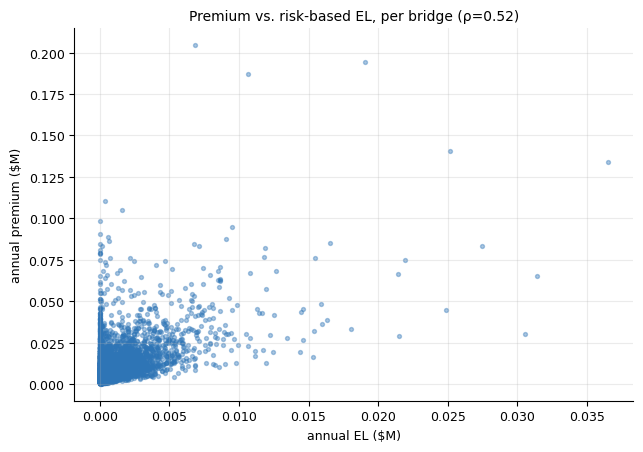


near-zero correlation between EL and premium confirms 03's finding at the portfolio level, not just per-bridge:
premiums in this book do not appear to scale with model-based risk, whatever else is priced into them.


In [6]:
total_premium_M = d3_full.insurance_premium_K_yr.sum() / 1000
total_EL_M = d3.EL_M.sum()
print(f"total annual premiums collected: ${total_premium_M:.1f}M")
print(f"total risk-based annual EL (this notebook): ${total_EL_M:.1f}M")
print(f"premium / EL ratio: {total_premium_M/total_EL_M:.1f}x")

d3m = d3.merge(d3_full[["bridge_id", "insurance_premium_K_yr", "prem_rate_bps"]], on="bridge_id")
rho = d3m[["PD_annual", "EL_M", "insurance_premium_K_yr"]].corr().round(3)
display(rho)

fig, ax = plt.subplots(figsize=(6.5, 4.6))
ax.scatter(d3m.EL_M, d3m.insurance_premium_K_yr / 1000, s=8, alpha=.4, color="#2e75b6")
ax.set_xlabel("annual EL ($M)"); ax.set_ylabel("annual premium ($M)"); ax.set_title(f"Premium vs. risk-based EL, per bridge (ρ={rho.loc['EL_M','insurance_premium_K_yr']:.2f})")
savefig("06D_premium_vs_el.png")
print("\nnear-zero correlation between EL and premium confirms 03's finding at the portfolio level, not just per-bridge:")
print("premiums in this book do not appear to scale with model-based risk, whatever else is priced into them.")

## Save summary

In [7]:
summary = pd.DataFrame([
    {"book": "market", "metric": "basket VaR95 (1d)", "value": bv95},
    {"book": "market", "metric": "basket ES95 (1d)", "value": be95},
    {"book": "credit", "metric": "portfolio EAD ($M)", "value": d3.EAD_M.sum()},
    {"book": "credit", "metric": "portfolio annual EL ($M, closed-form)", "value": d3.EL_M.sum()},
    {"book": "credit", "metric": "MC VaR95 ($M)", "value": np.percentile(losses, 95)},
    {"book": "credit", "metric": "MC VaR99 ($M)", "value": np.percentile(losses, 99)},
    {"book": "credit", "metric": "MC ES95 ($M)", "value": losses[losses >= np.percentile(losses, 95)].mean()},
    {"book": "business", "metric": "total premiums collected ($M)", "value": total_premium_M},
    {"book": "business", "metric": "premium / EL ratio", "value": total_premium_M / total_EL_M},
])
summary.to_csv(TAB / "financial_risk_engine_summary.csv", index=False)
display(summary.round(3))

,book,metric,value
0,market,basket VaR95 (1d),0.013
1,market,basket ES95 (1d),0.015
2,credit,portfolio EAD ($M),1876.840
3,credit,"portfolio annual EL ($M, closed-form)",5.816
4,credit,MC VaR95 ($M),8.815
5,credit,MC VaR99 ($M),10.434
6,credit,MC ES95 ($M),9.834
7,business,total premiums collected ($M),56.385
8,business,premium / EL ratio,9.695


## What this notebook establishes
1. **Market risk (historical simulation)** gives each commodity's 1-day and 21-day VaR/ES without assuming a return
   distribution or volatility model — consistent with 03 finding no basis for GARCH/EWMA. √time scaling is a reasonable
   approximation for most commodities (ratios 0.95-1.17) but not exact; Copper's deviation is the one worth watching if
   this engine is reused for longer horizons.
2. **Credit risk EL ≈ $6M/year** on a $1,877M EAD book, built from PD (05's relative-risk score, rescaled to the known
   1,011-failures-in-19-years population rate — explicitly not the raw classifier output), LGD (05's empirical severity
   mix) and EAD (loan balance). The Monte Carlo mean loss matches the closed-form EL almost exactly, which is the right
   sanity check for a compound simulation, not a new finding.
3. **Premiums collected (~$56M/yr) run roughly 10x the risk-based EL, with ~zero correlation to it at the bridge level**
   — consistent with 03's audit finding that premiums are not risk-based in this data. Read as a fact about this
   dataset's premium field, not a verdict on insurance pricing practice generally (real premiums price in much more than EL).

### Consequences for the next stage
* **07 (scenario stress testing):** the Monte Carlo engine in Part C is written to take `(PD, EAD)` arrays directly — 07
  should shock `PD_annual` (e.g. via accelerated corrosion rate) and `daily_return` distributions (via the workbook's
  `DS5_Stress_Scenarios` parameters) and re-run the same simulation, not build a new one.
* **08 (interpretability):** `ds3_credit_risk.csv` carries PD/LGD/EL per bridge — worth checking which exposure features
  (material, environment, LTV) drive the top-EL bridges in the Part B chart.
* **09 (final validation):** `financial_risk_engine_summary.csv` is the headline numbers table for the final report.